<a href="https://colab.research.google.com/github/ali-akbar-bermano/Lecture-series_ALI-AKBAR-BERMANO_G1A024041/blob/main/implementasi_lecture_series_pertemuan_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Digital Forensics: Analisis Log Server & Deteksi Serangan Siber (Log Forensics Engine)**

1. Import Library & Modul Python

In [1]:
# SEL 1: IMPORT LIBRARY & MODUL
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

print("✅ Sel 1: Modul analisis log & forensik digital berhasil diimpor!")

✅ Sel 1: Modul analisis log & forensik digital berhasil diimpor!


2. Simulasi Generator Log Server Mentah (Raw Access Log)

In [2]:
# SEL 2: GENERASI FILE LOG SERVER MENTAH (SIMULASI SERANGAN)
def generate_sample_server_logs(filename="access_log.log", num_records=200):
    """
    Membuat dataset log server sintetis yang berisi aktivitas normal
    dan ancaman serangan siber (Brute Force, SQLi, XSS).
    """
    normal_ips = ["192.168.1.10", "192.168.1.15", "10.0.0.5", "172.16.0.22"]
    attacker_ips = ["45.33.32.156", "185.220.101.5", "198.51.100.42"]

    user_agents = [
        "Mozilla/5.0 (Windows NT 10.0; Win64; x64)",
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7)",
        "python-requests/2.28.1"
    ]

    logs = []
    base_time = pd.Timestamp("2026-10-20 08:00:00")

    # 1. Trafik Normal
    for i in range(120):
        timestamp = (base_time + pd.Timedelta(seconds=i*15)).strftime("[%d/%b/%Y:%H:%M:%S +0000]")
        ip = np.random.choice(normal_ips)
        path = np.random.choice(["/home", "/about", "/products", "/contact", "/login"])
        method = "GET"
        status = 200
        logs.append(f'{ip} - - {timestamp} "{method} {path} HTTP/1.1" {status} 2340 "-" "{user_agents[0]}"')

    # 2. Serangan Brute Force (Percobaan Login Gagal Beruntun)
    attacker = attacker_ips[0]
    for i in range(40):
        timestamp = (base_time + pd.Timedelta(minutes=30, seconds=i*2)).strftime("[%d/%b/%Y:%H:%M:%S +0000]")
        logs.append(f'{attacker} - - {timestamp} "POST /login HTTP/1.1" 401 512 "-" "{user_agents[2]}"')
    # Login Berhasil setelah Brute Force
    timestamp = (base_time + pd.Timedelta(minutes=31, seconds=30)).strftime("[%d/%b/%Y:%H:%M:%S +0000]")
    logs.append(f'{attacker} - - {timestamp} "POST /login HTTP/1.1" 200 1024 "-" "{user_agents[2]}"')

    # 3. Serangan SQL Injection (SQLi Payload)
    sqli_attacker = attacker_ips[1]
    sqli_payloads = [
        "/products?id=1%20OR%201=1",
        "/admin/login.php?user=admin%27%20--",
        "/search?q=UNION%20SELECT%20username,password%20FROM%20users"
    ]
    for i, payload in enumerate(sqli_payloads):
        timestamp = (base_time + pd.Timedelta(hours=1, minutes=i*5)).strftime("[%d/%b/%Y:%H:%M:%S +0000]")
        logs.append(f'{sqli_attacker} - - {timestamp} "GET {payload} HTTP/1.1" 500 404 "-" "{user_agents[2]}"')

    # 4. Serangan Cross-Site Scripting (XSS)
    xss_attacker = attacker_ips[2]
    xss_payloads = [
        "/comment?msg=%3Cscript%3Ealert(%27XSS%27)%3C/script%3E",
        "/profile?name=%3Cimg%20src=x%20onerror=alert(1)%3E"
    ]
    for i, payload in enumerate(xss_payloads):
        timestamp = (base_time + pd.Timedelta(hours=2, minutes=i*2)).strftime("[%d/%b/%Y:%H:%M:%S +0000]")
        logs.append(f'{xss_attacker} - - {timestamp} "GET {payload} HTTP/1.1" 200 1520 "-" "{user_agents[1]}"')

    # Simpan ke File Log Mentah
    with open(filename, "w") as f:
        f.write("\n".join(logs))

    print(f"✅ Sel 2: File log simulasi '{filename}' berhasil dibuat ({len(logs)} baris data).")

# Jalankan Pembuatan Log
generate_sample_server_logs()

✅ Sel 2: File log simulasi 'access_log.log' berhasil dibuat (166 baris data).


3. Parsing Log Mentah ke DataFrame Terstruktur

In [3]:
# SEL 3: PARSING LOG MENTAH KE TAFIR TERSTRUKTUR
def parse_server_log(log_filepath="access_log.log"):
    """
    Mengekstrak komponen IP, Timestamp, HTTP Method, Request Path,
    Status Code, dan User Agent dari baris log mentah.
    """
    log_pattern = re.compile(
        r'^(?P<ip>\S+) \S+ \S+ \[(?P<timestamp>.*?)\] "(?P<method>\S+) (?P<path>\S+) \S+" (?P<status>\d+) (?P<bytes>\d+) ".*?" "(?P<user_agent>.*?)"'
    )

    parsed_records = []
    with open(log_filepath, "r") as f:
        for line in f:
            match = log_pattern.match(line)
            if match:
                data = match.groupdict()
                parsed_records.append(data)

    df = pd.DataFrame(parsed_records)

    # Konversi Tipe Data
    df['status'] = df['status'].astype(int)
    df['bytes'] = df['bytes'].astype(int)
    df['datetime'] = pd.to_datetime(df['timestamp'], format='%d/%b/%Y:%H:%M:%S %z')

    return df

# Eksekusi Parsing
df_logs = parse_server_log()
print("✅ Sel 3: Parsing log selesai!")
print(f"Total baris terekstrak: {len(df_logs)}\n")
df_logs.head()

✅ Sel 3: Parsing log selesai!
Total baris terekstrak: 166



,ip,timestamp,method,path,status,bytes,user_agent,datetime
0,192.168.1.15,20/Oct/2026:08:00:00 +0000,GET,/login,200,2340,Mozilla/5.0 (Windows NT 10.0; Win64; x64),2026-10-20 08:00:00+00:00
1,192.168.1.15,20/Oct/2026:08:00:15 +0000,GET,/home,200,2340,Mozilla/5.0 (Windows NT 10.0; Win64; x64),2026-10-20 08:00:15+00:00
2,192.168.1.10,20/Oct/2026:08:00:30 +0000,GET,/login,200,2340,Mozilla/5.0 (Windows NT 10.0; Win64; x64),2026-10-20 08:00:30+00:00
3,10.0.0.5,20/Oct/2026:08:00:45 +0000,GET,/about,200,2340,Mozilla/5.0 (Windows NT 10.0; Win64; x64),2026-10-20 08:00:45+00:00
4,10.0.0.5,20/Oct/2026:08:01:00 +0000,GET,/login,200,2340,Mozilla/5.0 (Windows NT 10.0; Win64; x64),2026-10-20 08:01:00+00:00


4. Machine Rule-Based Threat Detection Engine

In [4]:
# SEL 4: MACHINE DETEKSI SERANGAN SIBER
def detect_cyber_threats(df):
    """
    Menganalisis artefak log untuk menemukan indikator serangan (IoC).
    """
    threat_logs = []

    # 1. Deteksi Serangan Brute Force (Login Gagal > 5x dalam kurun waktu singkat)
    login_attempts = df[df['path'] == '/login']
    bf_grouped = login_attempts[login_attempts['status'] == 401].groupby('ip').size()
    brute_force_ips = bf_grouped[bf_grouped >= 5].index.tolist()

    # 2. Deteksi SQL Injection (SQLi Pattern Regex)
    sqli_pattern = re.compile(r"(%20OR%20|UNION%20SELECT|SELECT%20|WHERE%20|%27|--)", re.IGNORECASE)

    # 3. Deteksi Cross-Site Scripting (XSS Pattern Regex)
    xss_pattern = re.compile(r"(%3Cscript%3E|<script>|onerror=|alert\(|javascript:)", re.IGNORECASE)

    # Penandaan Jenis Serangan
    for idx, row in df.iterrows():
        threat_type = "Normal"

        # Cek Brute Force
        if row['ip'] in brute_force_ips and row['path'] == '/login':
            threat_type = "Brute Force Attack"

        # Cek SQL Injection
        elif sqli_pattern.search(row['path']):
            threat_type = "SQL Injection (SQLi)"

        # Cek XSS
        elif xss_pattern.search(row['path']):
            threat_type = "Cross-Site Scripting (XSS)"

        if threat_type != "Normal":
            threat_logs.append({
                'datetime': row['datetime'],
                'ip': row['ip'],
                'method': row['method'],
                'path': row['path'],
                'status': row['status'],
                'threat_type': threat_type
            })

    df_threats = pd.DataFrame(threat_logs)
    return df_threats, brute_force_ips

# Jalankan Deteksi
df_threats, flagged_bf_ips = detect_cyber_threats(df_logs)
print("✅ Sel 4: Deteksi Serangan Siber Selesai!")
print(f"Total Aktivitas Mencurigakan / Serangan Terdeteksi: {len(df_threats)} insiden.\n")
df_threats.head(10)

✅ Sel 4: Deteksi Serangan Siber Selesai!
Total Aktivitas Mencurigakan / Serangan Terdeteksi: 46 insiden.



,datetime,ip,method,path,status,threat_type
0,2026-10-20 08:30:00+00:00,45.33.32.156,POST,/login,401,Brute Force Attack
1,2026-10-20 08:30:02+00:00,45.33.32.156,POST,/login,401,Brute Force Attack
2,2026-10-20 08:30:04+00:00,45.33.32.156,POST,/login,401,Brute Force Attack
3,2026-10-20 08:30:06+00:00,45.33.32.156,POST,/login,401,Brute Force Attack
4,2026-10-20 08:30:08+00:00,45.33.32.156,POST,/login,401,Brute Force Attack
5,2026-10-20 08:30:10+00:00,45.33.32.156,POST,/login,401,Brute Force Attack
6,2026-10-20 08:30:12+00:00,45.33.32.156,POST,/login,401,Brute Force Attack
7,2026-10-20 08:30:14+00:00,45.33.32.156,POST,/login,401,Brute Force Attack
8,2026-10-20 08:30:16+00:00,45.33.32.156,POST,/login,401,Brute Force Attack
9,2026-10-20 08:30:18+00:00,45.33.32.156,POST,/login,401,Brute Force Attack


5. Visualisasi Forensik & Rekonstruksi Timeline Serangan

/tmp/ipykernel_2396/1974738007.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=threat_counts.index, y=threat_counts.values, ax=axes[0], palette='Reds_r')


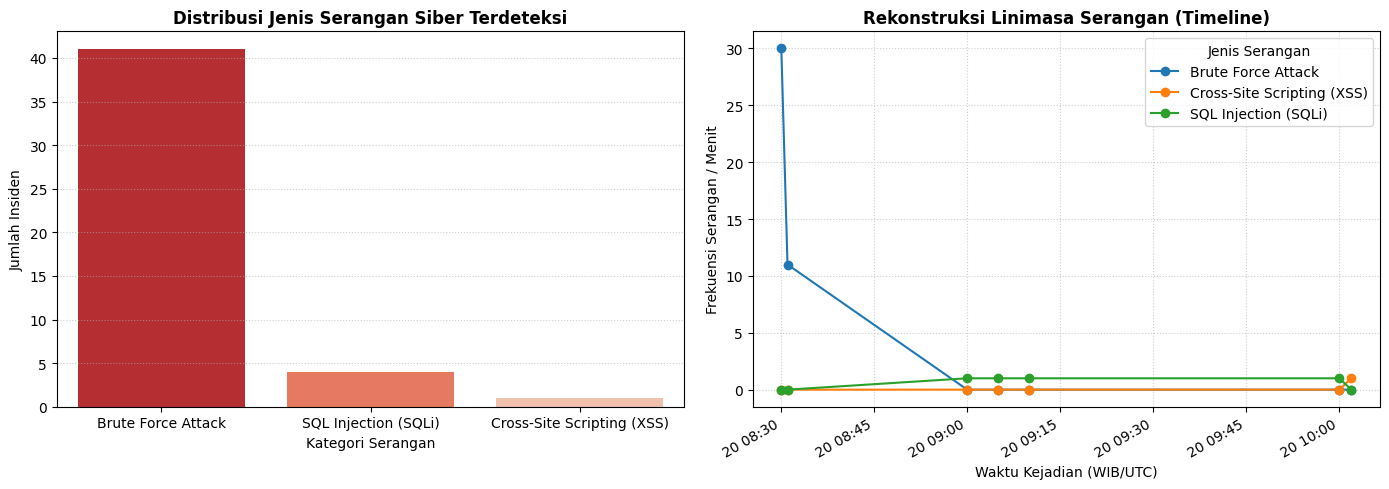

In [5]:
# SEL 5: VISUALISASI & REKONSTRUKSI LINIMASA SERANGAN
def visualize_forensic_analysis(df_logs, df_threats):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Grafik 1: Distribusi Jenis Serangan Terdeteksi
    threat_counts = df_threats['threat_type'].value_counts()
    sns.barplot(x=threat_counts.index, y=threat_counts.values, ax=axes[0], palette='Reds_r')
    axes[0].set_title('Distribusi Jenis Serangan Siber Terdeteksi', fontsize=12, fontweight='bold')
    axes[0].set_xlabel('Kategori Serangan')
    axes[0].set_ylabel('Jumlah Insiden')
    axes[0].grid(axis='y', linestyle=':', alpha=0.6)

    # Grafik 2: Rekonstruksi Waktu Aktivitas Serangan (Timeline)
    df_threats['minute'] = df_threats['datetime'].dt.floor('min')
    timeline_data = df_threats.groupby(['minute', 'threat_type']).size().unstack(fill_value=0)

    timeline_data.plot(kind='line', marker='o', ax=axes[1])
    axes[1].set_title('Rekonstruksi Linimasa Serangan (Timeline)', fontsize=12, fontweight='bold')
    axes[1].set_xlabel('Waktu Kejadian (WIB/UTC)')
    axes[1].set_ylabel('Frekuensi Serangan / Menit')
    axes[1].grid(True, linestyle=':', alpha=0.6)
    axes[1].legend(title='Jenis Serangan')

    plt.tight_layout()
    plt.show()

# Tampilkan Visualisasi
visualize_forensic_analysis(df_logs, df_threats)

6. Generating Laporan Hasil Laporan Forensik Digital (Incident Report)

In [6]:
# SEL 6: DIGITIAL FORENSICS INCIDENT REPORT
def generate_forensic_report(df_logs, df_threats, bf_ips):
    total_logs = len(df_logs)
    total_threats = len(df_threats)
    unique_attackers = df_threats['ip'].unique()

    print("="*60)
    print(" 🛡️ DIGITAL FORENSICS & INCIDENT RESPONSE (DFIR) REPORT")
    print("="*60)
    print(f" • Total Baris Log Menganalisis : {total_logs} baris")
    print(f" • Total Anomali/Serangan      : {total_threats} kejadian")
    print(f" • Alamat IP Penyerang (Target): {', '.join(unique_attackers)}")
    print("-"*60)
    print(" 📌 DETAIL RINGKASAN ANCAMAN:")

    for threat_type, group in df_threats.groupby('threat_type'):
        ip_list = group['ip'].unique()
        print(f"   > {threat_type}: {len(group)} kali dari IP {list(ip_list)}")

    print("-"*60)
    print(" 💡 REKOMENDASI TINDAKAN PENCEGAHAN (MITIGASI):")
    print(f"   1. Blokir IP berikut pada Firewall/WAF: {list(unique_attackers)}")
    print(f"   2. Terapkan Rate Limiting / Fail2Ban pada endpoint /login untuk IP: {bf_ips}")
    print("   3. Gunakan Parameterized Queries (Prepared Statements) untuk mencegah SQLi.")
    print("   4. Terapkan Input Sanitization & Content Security Policy (CSP) untuk mencegah XSS.")
    print("="*60 + "\n")

# Cetak Laporan Forensik
generate_forensic_report(df_logs, df_threats, flagged_bf_ips)

 🛡️ DIGITAL FORENSICS & INCIDENT RESPONSE (DFIR) REPORT
 • Total Baris Log Menganalisis : 166 baris
 • Total Anomali/Serangan      : 46 kejadian
 • Alamat IP Penyerang (Target): 45.33.32.156, 185.220.101.5, 198.51.100.42
------------------------------------------------------------
 📌 DETAIL RINGKASAN ANCAMAN:
   > Brute Force Attack: 41 kali dari IP ['45.33.32.156']
   > Cross-Site Scripting (XSS): 1 kali dari IP ['198.51.100.42']
   > SQL Injection (SQLi): 4 kali dari IP ['185.220.101.5', '198.51.100.42']
------------------------------------------------------------
 💡 REKOMENDASI TINDAKAN PENCEGAHAN (MITIGASI):
   1. Blokir IP berikut pada Firewall/WAF: ['45.33.32.156', '185.220.101.5', '198.51.100.42']
   2. Terapkan Rate Limiting / Fail2Ban pada endpoint /login untuk IP: ['45.33.32.156']
   3. Gunakan Parameterized Queries (Prepared Statements) untuk mencegah SQLi.
   4. Terapkan Input Sanitization & Content Security Policy (CSP) untuk mencegah XSS.

